# Лабораторная №2. Шаврин А.П. Виноградова М.О.

## Imports

In [757]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from skimage.draw import line as skimage_line
from scipy.ndimage import distance_transform_edt, maximum_filter

## Core

In [758]:
@dataclass(frozen=True, slots=True)
class Point:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Vector:
    x: float
    y: float


@dataclass(frozen=True, slots=True)
class Segment:
    a: Point
    b: Point


@dataclass(frozen=True, slots=True)
class Ray:
    origin: Point
    direction: Vector

    @classmethod
    def from_angle(cls, origin: Point, angle: float) -> Ray:
        return cls(origin, Vector(math.cos(angle), math.sin(angle)))


@dataclass(frozen=True, slots=True)
class Pose:
    position: Point
    theta: float

    def compose(self, other: Pose) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = c * other.position.x - s * other.position.y + self.position.x,
                y = s * other.position.x + c * other.position.y + self.position.y
            ),
            theta = self.theta + other.theta,
        )

    def inverse(self) -> Pose:
        c, s = math.cos(self.theta), math.sin(self.theta)
        return Pose(
            position=Point(
                x = -c * self.position.x - s * self.position.y,
                y = s * self.position.x - c * self.position.y
            ),
            theta = -self.theta,
        )

    def apply(self, points: np.ndarray) -> np.ndarray:
        c, s = math.cos(self.theta), math.sin(self.theta)
        R = np.array([[c, -s], [s, c]])
        return points @ R.T + np.array([self.position.x, self.position.y])


@dataclass(frozen=True, slots=True)
class Scan:
    angles: np.ndarray
    ranges: np.ndarray

    def __post_init__(self):
        if len(self.angles) != len(self.ranges):
            raise ValueError(f"angles ({len(self.angles)}) != ranges ({len(self.ranges)})")
        self.angles.flags.writeable = False
        self.ranges.flags.writeable = False


@dataclass
class Room:
    polygon: list[Point]    # вершины против часовой

    @property
    def n_vertices(self) -> int:
        return len(self.polygon)

    @cached_property
    def segments(self) -> list[Segment]:
        n = self.n_vertices
        return [Segment(self.polygon[i], self.polygon[(i+1)%n]) for i in range(n)]

    @cached_property
    def area(self) -> float:
        s = 0.0
        for seg in self.segments:
            s += seg.a.x * seg.b.y - seg.b.x * seg.a.y
        return abs(s) / 2.0


@dataclass(frozen=True)
class GridSpec:
    origin: Point
    resolution: float
    shape: tuple[int, int]

    @property
    def height(self) -> int:
        return self.shape[0]

    @property
    def width(self) -> int:
        return self.shape[1]

    @classmethod
    def covering(cls, points: np.ndarray, margin: float = 1.0, resolution: float = 0.05) -> GridSpec:
        x0, y0 = points.min(axis=0) - margin
        x1, y1 = points.max(axis=0) + margin
        W = int(np.ceil((x1 - x0) / resolution))
        H = int(np.ceil((y1 - y0) / resolution))
        return cls(Point(float(x0), float(y0)), resolution, (H, W))

    def expanded(self, margin: float) -> GridSpec:
        margin_cells = int(np.ceil(margin / self.resolution))
        if margin_cells <= 0:
            return self
        distance = margin_cells * self.resolution
        return GridSpec(
            Point(self.origin.x - distance, self.origin.y - distance),
            self.resolution,
            (self.height + 2 * margin_cells, self.width + 2 * margin_cells),
        )

    def to_cell(self, points: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        fx = (points[:, 0] - self.origin.x) / self.resolution
        fy = (points[:, 1] - self.origin.y) / self.resolution
        return np.floor(fx).astype(int), np.floor(fy).astype(int)

    def contains(self, cell_x: np.ndarray, cell_y: np.ndarray) -> np.ndarray:
        return (cell_x >= 0) & (cell_x < self.width) & (cell_y >= 0) & (cell_y < self.height)

    @property
    def extent(self) -> tuple[float, float, float, float]:
        x0, y0 = self.origin.x, self.origin.y
        return x0, x0 + self.width * self.resolution, y0, y0 + self.height * self.resolution


In [759]:
def polar_to_local(scan: Scan) -> np.ndarray:
    return np.column_stack([scan.ranges * np.cos(scan.angles), scan.ranges * np.sin(scan.angles)])

In [760]:
def bresenham(x0: int, y0: int, x1: int, y1: int) -> list[tuple[int, int]]:
    rr, cc = skimage_line(y0, x0, y1, x1)
    return list(zip(cc.tolist(), rr.tolist()))

## Pose generator

In [761]:
class PoseGenerator:
    def __init__(self, room: Room, rng, wall_margin: float = 0.5):
        self.room = room
        self.rng = rng
        self.wall_margin = wall_margin
        # bbox для быстрой выборки
        xs = [p.x for p in room.polygon]
        ys = [p.y for p in room.polygon]
        self._xmin, self._xmax = min(xs), max(xs)
        self._ymin, self._ymax = min(ys), max(ys)

    @staticmethod
    def _signed_dist_to_wall(point: Point, segment: Segment) -> float:
        ax, ay = segment.a.x, segment.a.y
        ex, ey = segment.b.x - ax, segment.b.y - ay
        cross = ex * (point.y - ay) - ey * (point.x - ax)
        return cross / math.hypot(ex, ey)

    def is_valid_point(self, point: Point) -> bool:
        return all(
            self._signed_dist_to_wall(point, seg) >= self.wall_margin
            for seg in self.room.segments
        )

    def random_point(self, tries: int = 10_000) -> Point:
        for _ in range(tries):
            p = Point(
                self.rng.uniform(self._xmin, self._xmax),
                self.rng.uniform(self._ymin, self._ymax),
            )
            if self.is_valid_point(p):
                return p
        raise RuntimeError("не удалось сгенерировать валидную точку")

    def random(self, tries: int = 10_000) -> Pose:
        return Pose(self.random_point(tries), self.rng.uniform(-np.pi, np.pi))

    @staticmethod
    def _greedy_order(start: Point, points: list[Point]) -> list[Point]:
        """Nearest-neighbor: 2-approximation для TSP. Для N<=10 можно брутфорсом."""
        remaining = list(points)
        ordered, current = [], start
        while remaining:
            i = min(
                range(len(remaining)),
                key=lambda k: (remaining[k].x - current.x) ** 2 + (remaining[k].y - current.y) ** 2,
            )
            current = remaining.pop(i)
            ordered.append(current)
        return ordered

    def trajectory(
        self,
        n_scans: int,
        n_waypoints: int | None = None,
        greedy_order: bool = True,
    ) -> list[Pose]:
        n_waypoints = n_waypoints if n_waypoints is not None else max(2, n_scans // 3)

        start = self.random_point()
        waypoints = [self.random_point() for _ in range(n_waypoints)]

        if greedy_order and len(waypoints) > 1:
            waypoints = self._greedy_order(start, waypoints)
        path = [start] + waypoints
        seg_len = [
            math.hypot(path[i+1].x - path[i].x, path[i+1].y - path[i].y)
            for i in range(len(path) - 1)
        ]
        total = sum(seg_len)
        if total < 1e-9:
            return [Pose(start, 0.0)] * n_scans
        step = total / max(1, n_scans - 1)

        poses: list[Pose] = []
        acc = 0.0
        seg = 0
        for k in range(n_scans):
            target = k * step
            while seg < len(seg_len) - 1 and acc + seg_len[seg] < target - 1e-9:
                acc += seg_len[seg]
                seg += 1
            t = (target - acc) / seg_len[seg] if seg_len[seg] > 1e-12 else 0.0
            t = min(max(t, 0.0), 1.0)
            a, b = path[seg], path[seg + 1]
            pt = Point(a.x + t * (b.x - a.x), a.y + t * (b.y - a.y))
            # "смотрим вперёд" по направлению текущего сегмента
            heading = math.atan2(b.y - a.y, b.x - a.x)
            poses.append(Pose(pt, heading))

        return poses

## RayCaster

In [762]:
class RayCaster:
    _EPS = 1e-9
    _EPS_PARALLEL = 1e-9

    def intersect_segment(self, ray: Ray, segment: Segment) -> float | None:
        ox, oy = ray.origin.x, ray.origin.y
        dx, dy = ray.direction.x, ray.direction.y
        ax, ay = segment.a.x, segment.a.y
        ex, ey = segment.b.x - ax, segment.b.y - ay

        denom = dx * ey - dy * ex
        if abs(denom) < self._EPS_PARALLEL * math.hypot(ex, ey):
            return None

        t = ((ax - ox) * ey - (ay - oy) * ex) / denom
        u = ((ax - ox) * dy - (ay - oy) * dx) / denom
        if t > self._EPS and 0.0 <= u <= 1.0:
            return float(t)
        return None


    def cast(self, ray: Ray, room: Room) -> float | None:
        best = None
        for segment in room.segments:
            t = self.intersect_segment(ray, segment)
            if t is not None and (best is None or t < best):
                best = t
        return best

## Lidar

In [763]:
class Lidar:
    def __init__(
        self, 
        rng: np.random.Generator,
        ray_caster: RayCaster, 
        room: Room,
        angle_step: float = math.pi / 360, 
        max_range: float = 12.0, 
        noise_std: float = 0.02,
    ):
        self.ray_caster = ray_caster
        self.angle_step = angle_step
        self.max_range = max_range
        self.noise_std = noise_std
        self.rng = rng
        self.room = room

    @property
    def num_rays(self) -> int:
        return int(round(2 * math.pi / self.angle_step))

    def scan(self, pose: Pose) -> Scan:
        n = self.num_rays
        angles = np.arange(n) * self.angle_step
        ranges = np.empty(n)

        for i, angle in enumerate(angles):
            ray = Ray.from_angle(pose.position, pose.theta + angle)
            t = self.ray_caster.cast(ray, self.room)
            ranges[i] = t if t is not None and t < self.max_range else math.nan

        ranges = ranges + self.rng.normal(0, self.noise_std, len(ranges))

        mask = ~np.isnan(ranges)
        return Scan(angles=angles[mask], ranges=ranges[mask])

## Map

In [764]:
class OccupancyGrid:
    def __init__(
        self, 
        grid_spec: GridSpec, 
        prob_hit=0.7, 
        prob_miss=0.4, 
        log_odds_min=-2.0, 
        log_odds_max=3.5
    ):
        self.grid_spec = grid_spec
        self.log_odds = np.zeros(grid_spec.shape, np.float32)
        self.prob_hit = prob_hit
        self.prob_miss = prob_miss
        self.log_odds_hit  = math.log(prob_hit  / (1 - prob_hit))
        self.log_odds_miss = math.log(prob_miss / (1 - prob_miss))
        self.log_odds_min = log_odds_min
        self.log_odds_max = log_odds_max

    def integrate(self, scan: Scan, pose: Pose) -> OccupancyGrid:
        points = pose.apply(polar_to_local(scan))
        cell_x, cell_y = self.grid_spec.to_cell(points)
        in_bounds = self.grid_spec.contains(cell_x, cell_y)

        ox, oy = self.grid_spec.to_cell(np.array([[pose.position.x, pose.position.y]]))
        ox, oy = int(ox[0]), int(oy[0])
        for hit_x, hit_y in zip(cell_x[in_bounds], cell_y[in_bounds]):
            for px, py in bresenham(ox, oy, hit_x, hit_y)[:-1]:
                if 0 <= py < self.grid_spec.shape[0] and 0 <= px < self.grid_spec.shape[1]:
                    self.log_odds[py, px] += self.log_odds_miss

        np.add.at(self.log_odds, (cell_y[in_bounds], cell_x[in_bounds]), self.log_odds_hit)
        np.clip(self.log_odds, self.log_odds_min, self.log_odds_max, out=self.log_odds)
        return self

    def probabilities(self) -> np.ndarray:
        probabilities = (1.0 / (1.0 + np.exp(-self.log_odds))).astype(np.float32)
        return probabilities

    def occupied(self, threshold: float = 0.65) -> np.ndarray:
        return self.probabilities() > threshold

    def free_area(self, free_threshold: float = 0.35) -> float:
        probs = self.probabilities()
        free = probs <= free_threshold
        return float(free.sum() * self.grid_spec.resolution**2)

## Correlative Scan Matching

In [765]:
class LikelihoodField:
    def __init__(self, occupancy_grid: OccupancyGrid, sigma: float = 0.15, occupied_threshold: float = 0.65, margin: float = 0.0):
        self.sigma = sigma
        self.grid_spec = occupancy_grid.grid_spec.expanded(margin)

        ys, xs = np.nonzero(occupancy_grid.occupied(occupied_threshold))
        world = np.column_stack([
            occupancy_grid.grid_spec.origin.x + (xs + 0.5) * occupancy_grid.grid_spec.resolution,
            occupancy_grid.grid_spec.origin.y + (ys + 0.5) * occupancy_grid.grid_spec.resolution,
        ])
        occupied = np.zeros(self.grid_spec.shape, bool)
        cell_x, cell_y = self.grid_spec.to_cell(world)
        in_bounds = self.grid_spec.contains(cell_x, cell_y)
        occupied[cell_y[in_bounds], cell_x[in_bounds]] = True

        distance = distance_transform_edt(~occupied) * self.grid_spec.resolution
        self.likelihood_field = np.exp(-0.5 * (distance / sigma) ** 2).astype(np.float32)
        self._hier = {}

    def score(self, points: np.ndarray, grid: np.ndarray | None = None) -> float:
        fx = (points[:, 0] - self.grid_spec.origin.x) / self.grid_spec.resolution - 0.5
        fy = (points[:, 1] - self.grid_spec.origin.y) / self.grid_spec.resolution - 0.5
        cell_x0 = np.floor(fx).astype(int)
        cell_y0 = np.floor(fy).astype(int)
        fraction_x = fx - cell_x0
        fraction_y = fy - cell_y0
        H, W = self.grid_spec.shape
        cell_x0_clipped = np.clip(cell_x0, 0, W - 1)
        cell_x1_clipped = np.clip(cell_x0 + 1, 0, W - 1)
        cell_y0_clipped = np.clip(cell_y0, 0, H - 1)
        cell_y1_clipped = np.clip(cell_y0 + 1, 0, H - 1)
        f = self.likelihood_field if grid is None else grid
        return float((
            ((f[cell_y0_clipped, cell_x0_clipped] * (1 - fraction_x) + f[cell_y0_clipped, cell_x1_clipped] * fraction_x) * (1 - fraction_y))
            + ((f[cell_y1_clipped, cell_x0_clipped] * (1 - fraction_x) + f[cell_y1_clipped, cell_x1_clipped] * fraction_x) * fraction_y)
        ).sum())

    def hierarchy(self, max_hierarchy_level: int):
        if max_hierarchy_level not in self._hier:
            grids = [self.likelihood_field]
            for hierarchy_level in range(1, max_hierarchy_level + 1):
                grids.append(maximum_filter(self.likelihood_field, size=2 ** hierarchy_level + 1, mode="constant"))
            self._hier[max_hierarchy_level] = grids
        return self._hier[max_hierarchy_level]


In [766]:
class ScanMatcher:
    def required_margin(
        self, 
        max_scan_radius: float, 
        sigma: float, 
        resolution: float,
        window_xy: float,
        window_theta: float,
    ) -> float:
        rotation_margin = 2.0 * max_scan_radius * math.sin(
            min(window_theta, math.pi) / 2.0
        )
        return window_xy + rotation_margin + 3.0 * sigma + 2.0 * resolution

    def match(
        self, 
        likelihood_field: LikelihoodField, 
        scan: Scan, 
        prior_pose: Pose | None = None,
        window_xy: float | None = None,
        window_theta: float | None = None,
    ) -> Pose:
        prior_pose = prior_pose or Pose(Point(0.0, 0.0), 0.0)
        points = polar_to_local(scan)
        if len(points) == 0:
            return prior_pose

        r = likelihood_field.grid_spec.resolution
        max_scan_radius = float(np.linalg.norm(points, axis=1).max())
        theta_step = 2.0 * math.asin(r / (2.0 * max_scan_radius)) if max_scan_radius > r else math.pi / 18.0

        xy_step_count = max(1, int(window_xy / r))
        theta_step_count = max(1, int(window_theta / theta_step))

        max_hierarchy_level = max(1, math.ceil(math.log2(2 * xy_step_count + 1)))
        max_hierarchy_level = min(max_hierarchy_level, 6)
        precomputed_fields = likelihood_field.hierarchy(max_hierarchy_level)

        def pose_of(cell_x: int, cell_y: int, cell_theta: int, hierarchy_level: int) -> Pose:
            off = ((2 ** hierarchy_level) - 1) / 2.0
            return Pose(
                Point(
                    prior_pose.position.x + r * (cell_x + off),
                    prior_pose.position.y + r * (cell_y + off)
                ),
                prior_pose.theta + theta_step * (cell_theta + off),
            )

        def score(cell_x, cell_y, cell_theta, hierarchy_level, grid) -> float:
            return likelihood_field.score(pose_of(cell_x, cell_y, cell_theta, hierarchy_level).apply(points), grid)

        coarse_step = 2 ** max_hierarchy_level
        stack = [
            (cell_x, cell_y, cell_theta, max_hierarchy_level)
            for cell_x in range(-xy_step_count, xy_step_count + 1, coarse_step)
            for cell_y in range(-xy_step_count, xy_step_count + 1, coarse_step)
            for cell_theta in range(-theta_step_count, theta_step_count + 1, coarse_step)
        ]
        stack = [(score(*candidate, precomputed_fields[candidate[3]]), candidate) for candidate in stack]
        stack.sort(key=lambda scored_candidate: scored_candidate[0])

        best_score, best_pose = -np.inf, None
        while stack:
            bound, (cell_x, cell_y, cell_theta, hierarchy_level) = stack.pop()
            if bound <= best_score:
                continue
            if hierarchy_level == 0:
                current_score = score(cell_x, cell_y, cell_theta, 0, likelihood_field.likelihood_field)
                if current_score > best_score:
                    best_score, best_pose = current_score, pose_of(cell_x, cell_y, cell_theta, 0)
            else:
                next_hierarchy_level = hierarchy_level - 1
                child_step = 2 ** next_hierarchy_level
                children = [
                    (cell_x + sx * child_step, cell_y + sy * child_step, cell_theta + st * child_step, next_hierarchy_level)
                    for sx in (0, 1) for sy in (0, 1) for st in (0, 1)
                ]
                children = [
                    child for child in children
                    if -xy_step_count <= child[0] <= xy_step_count
                    and -xy_step_count <= child[1] <= xy_step_count
                    and -theta_step_count <= child[2] <= theta_step_count
                ]
                scored = [(score(*c, precomputed_fields[next_hierarchy_level]), c) for c in children]
                scored.sort(key=lambda scored_candidate: scored_candidate[0])
                for bound, candidate in scored:
                    stack.append((bound, candidate))

        return best_pose if best_pose is not None else prior_pose


## Vizualizer

In [ ]:
class ScanVisualizer:
    def __init__(self, room: Room, figsize=(14, 12), dpi=100):
        self.room = room
        self.figsize = figsize
        self.dpi = dpi

    def _draw_room(self, ax):
        poly = np.array([[point.x, point.y] for point in self.room.polygon])
        poly = np.vstack([poly, poly[0]])
        ax.plot(poly[:, 0], poly[:, 1], "k-", lw=2, label="room")

    def _draw_robot(self, ax, pose: Pose, color, label=None):
        ax.plot(
            pose.position.x,
            pose.position.y,
            "o",
            color=color,
            markeredgecolor="black",
            ms=9,
            label=label
        )
        ax.arrow(
            pose.position.x,
            pose.position.y,
            0.6 * math.cos(pose.theta),
            0.6 * math.sin(pose.theta),
            head_width=0.2,
            color=color,
            length_includes_head=True
        )

    def _draw_scan_local(self, ax, points, color, title):
        ax.scatter(*points.T, s=4, c=color, alpha=0.7)
        ax.plot(0, 0, "o", color=color, markeredgecolor="black", ms=10)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color=color, length_includes_head=True)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_xlim(-10, 10)
        ax.set_ylim(-10, 10)
        ax.set_title(title)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")

    def plot_scan_setup(
        self, 
        pose1: Pose, 
        pose2: Pose, 
        scan1: Scan, 
        scan2: Scan, 
        delta_true, 
        figsize=(14, 12)
    ):
        pts1_local = polar_to_local(scan1)
        pts2_local = polar_to_local(scan2)
        pts1_world = pose1.apply(pts1_local)
        pts2_world = pose2.apply(pts2_local)

        fig, axes = plt.subplots(2, 2, figsize=figsize)

        ax = axes[0, 0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T, s=4, c="tab:blue",  alpha=0.7, label="scan1")
        ax.scatter(*pts2_world.T, s=4, c="tab:green", alpha=0.7, label="scan2")
        self._draw_robot(ax, pose1, "tab:blue",  "pose1")
        self._draw_robot(ax, pose2, "tab:green", "pose2")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title("World: room + both scans + both poses")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        self._draw_scan_local(axes[0, 1], pts1_local, "tab:blue", f"scan1 in robot-1 frame ({len(scan1.ranges)} rays)")
        self._draw_scan_local(axes[1, 0], pts2_local, "tab:green", f"scan2 in robot-2 frame ({len(scan2.ranges)} rays)")

        ax = axes[1, 1]
        ax.scatter(*pts1_local.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        ax.scatter(*delta_true.apply(pts2_local).T, s=4, c="tab:green", alpha=0.7, label="scan2 x delta_true")
        ax.plot(0, 0, "o", color="black", ms=8)
        ax.arrow(0, 0, 0.6, 0, head_width=0.2, color="black", length_includes_head=True)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title(f"Target: both in robot-1 frame\n delta_true = ({delta_true.position.x:+.2f}, {delta_true.position.y:+.2f}, {math.degrees(delta_true.theta):+.1f})")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        return fig, axes

    def plot_match_result(
        self,
        pose1: Pose,
        pose2: Pose,
        scan1: Scan, 
        scan2: Scan, 
        occupancy_grid: OccupancyGrid, 
        delta_est: Pose,
        rel_pos_err: float | None = None,
        show: bool = True
    ):
        pts1 = polar_to_local(scan1)
        pts2 = polar_to_local(scan2)

        pts1_world = pose1.apply(pts1)
        pts2_world = pose2.apply(pts2)

        p2_est_in1 = delta_est.apply(pts2)

        fig, axes = plt.subplots(1, 3, figsize=(21, 7))

        ax = axes[0]
        self._draw_room(ax)
        ax.scatter(*pts1_world.T, s=3, c="tab:blue",  alpha=0.6, label="scan1")
        ax.scatter(*pts2_world.T, s=3, c="tab:green", alpha=0.5, label="scan2")
        self._draw_robot(ax, pose1, "tab:blue", "pose1")
        self._draw_robot(ax, pose2, "tab:green", "pose2")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        ax.set_title("World: room + scans + poses")
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        ax = axes[1]
        prob = occupancy_grid.probabilities()
        ax.imshow(prob, origin="lower", extent=occupancy_grid.grid_spec.extent, cmap="Greys", vmin=0, vmax=1)
        ax.scatter(*pts1.T, s=4, c="tab:blue", alpha=0.7, label="scan1")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")

        x0, x1, y0, y1 = occupancy_grid.grid_spec.extent
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)

        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        title = "Occupancy map (scan1 only)"
       
        ax.set_title(title)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        ax = axes[2]
        ax.scatter(*pts1.T, s=4, c="tab:blue", alpha=0.6, label="scan1")
        ax.scatter(*p2_est_in1.T, s=4, c="tab:red",  alpha=0.6, label=r"scan2 x delta_est")
        self._draw_robot(ax, Pose(Point(0.0, 0.0), 0.0), "lime", "robot-1")
        self._draw_robot(ax, delta_est, "tab:green", "robot-2 (est)")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
        title3 = f"Aligned in robot-1 frame\n delta_est = ({delta_est.position.x:+.2f}, {delta_est.position.y:+.2f}, {math.degrees(delta_est.theta):+.1f})"
        if rel_pos_err is not None:
            title3 += f"\nerr = {rel_pos_err:.2f}% of diag"
        ax.set_title(title3)
        ax.set_xlabel("x, m")
        ax.set_ylabel("y, m")
        ax.legend(fontsize=8, loc="best")

        plt.tight_layout()
        if show:
            plt.show()
        return fig, axes

    def _draw_trajectory_with_arrows(self, ax, xy, color, label):
        ax.plot(xy[:, 0], xy[:, 1], "-", color=color, lw=1, alpha=0.5, label=label)
        for i in range(len(xy) - 1):
            ax.annotate("", xy=xy[i + 1], xytext=xy[i],
                        arrowprops=dict(arrowstyle="->", color=color, lw=1.2))
        ax.scatter(xy[:, 0], xy[:, 1], s=24, c=color, zorder=3,
                edgecolors="black", linewidths=0.5)

        for i, (x, y) in enumerate(xy):
            ax.annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8, color=color, zorder=4)

    def plot_slam_result(self, slam, true_poses: list[Pose], figsize=(18, 8), show=True):
        start_pose = true_poses[0]

        true_xy_world = np.array([[p.position.x, p.position.y] for p in true_poses])
        est_poses_world = [start_pose.compose(h["pose_est"]) for h in slam.history]
        est_xy_world = np.array([[p.position.x, p.position.y] for p in est_poses_world])

        true_poses_slam = [start_pose.inverse().compose(p) for p in true_poses]
        true_xy_slam = np.array([[p.position.x, p.position.y] for p in true_poses_slam])
        est_xy_slam = np.array([[h["pose_est"].position.x, h["pose_est"].position.y]
                                for h in slam.history])

        room_world = np.array([[p.x, p.y] for p in self.room.polygon])
        room_slam = start_pose.inverse().apply(room_world)
        room_slam = np.vstack([room_slam, room_slam[0]])

        S_true = self.room.area
        S_slam = slam.grid.free_area(free_threshold=0.35)
        err = abs(S_slam - S_true) / S_true

        fig, axes = plt.subplots(1, 2, figsize=figsize)

        ax = axes[0]
        self._draw_room(ax)
        self._draw_trajectory_with_arrows(ax, true_xy_world, "tab:blue", "true (world)")
        self._draw_trajectory_with_arrows(ax, est_xy_world,  "tab:red",  "est (world)")
        self._draw_robot(ax, start_pose, "tab:green", "start")
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="best")
        ax.set_title("World: room + true/est trajectories (arrows = переходы)")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")

        ax = axes[1]
        ax.imshow(slam.grid.probabilities(), origin="lower",
                extent=slam.grid.grid_spec.extent, cmap="Greys", vmin=0, vmax=1)
        ax.plot(room_slam[:, 0], room_slam[:, 1], "k-", lw=1.5, alpha=0.6, label="room (local)")
        self._draw_trajectory_with_arrows(ax, true_xy_slam, "tab:blue", "true")
        self._draw_trajectory_with_arrows(ax, est_xy_slam,  "tab:red",  "est")
        ax.plot(0, 0, "ks", ms=10, label="start (SLAM origin)")
        ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="best")
        ax.set_title(f"Occupancy (SLAM-frame): S_slam={S_slam:.2f}, "
                    f"S_true={S_true:.2f}, err={err*100:.1f}%")
        ax.set_xlabel("x, m"); ax.set_ylabel("y, m")

        plt.tight_layout()
        if show: plt.show()
        return fig, axes, {"S_true": S_true, "S_slam": S_slam, "err": err}

## SLAM

In [ ]:
class SLAM:
    def __init__(
        self,
        rng: np.random.Generator,
        room: Room,
        scan_matcher: ScanMatcher,
        likelihood_sigma: float = 0.12,
        occupied_threshold: float = 0.65,
        odometry_sigma_xy: float = 0.2,
        odometry_sigma_theta: float = math.radians(5.0),
        window_sigmas: float = 3.0,
    ):
        self.room = room
        self.rng = rng
        self.pose_generator = PoseGenerator(rng=self.rng, room=self.room, wall_margin=0.6)
        self.lidar = Lidar(rng=self.rng, room=self.room, ray_caster=RayCaster(), angle_step=math.pi / 360, max_range=10.0, noise_std=0.02)
        self.scan_matcher = scan_matcher
        self.likelihood_sigma = likelihood_sigma
        self.occupied_threshold = occupied_threshold
        self.odometry_sigma_xy = odometry_sigma_xy
        self.odometry_sigma_theta = odometry_sigma_theta
        self.window_sigmas = window_sigmas

        self.history: list[dict] = []
        self.grid = None
        self.poses_world: list[Pose] = []
        self.poses_local: list[Pose] = []


    def _build_likelihood(self, scan, window_xy, window_theta):
        pts = polar_to_local(scan)
        max_scan_radius = float(np.linalg.norm(pts, axis=1).max()) if len(pts) else 0.0
        margin = self.scan_matcher.required_margin(
            max_scan_radius=max_scan_radius,
            sigma=self.likelihood_sigma,
            resolution=self.grid.grid_spec.resolution,
            window_xy=window_xy,
            window_theta=window_theta,
        )
        return LikelihoodField(
            self.grid, 
            sigma=self.likelihood_sigma,
            occupied_threshold=self.occupied_threshold, 
            margin=margin
        )

    def init(self, n_poses: int, n_waypoints: int, greedy_order: bool = False) -> None:
        self.poses_world = self.pose_generator.trajectory(
            n_scans=n_poses, n_waypoints=n_waypoints, greedy_order=greedy_order,
        )
        start_inv = self.poses_world[0].inverse()
        self.poses_local = [start_inv.compose(p) for p in self.poses_world]
        room_world = np.array([[p.x, p.y] for p in self.room.polygon])
        room_local = start_inv.apply(room_world)
        grid_spec = GridSpec.covering(room_local, margin=1.0, resolution=0.05)
        self.grid = OccupancyGrid(grid_spec)

    def step(self, i: int) -> Pose:
        if not (0 <= i < len(self.poses_world)):
            raise ValueError(f"i={i} out of range [0, {len(self.poses_world)})")

        t0 = time.perf_counter()
        true_world = self.poses_world[i]
        true_local = self.poses_local[i]
        scan = self.lidar.scan(true_world)

        if i == 0:
            est = Pose(Point(0.0, 0.0), 0.0)
            self.grid.integrate(scan, est)
            t1 = time.perf_counter()
            self.history.append({
                "pose_est": est, 
                "t_step": t1 - t0,
            })
            return est

        prior = Pose(
            Point(true_local.position.x + self.rng.normal(0.0, self.odometry_sigma_xy),
                  true_local.position.y + self.rng.normal(0.0, self.odometry_sigma_xy)),
            true_local.theta + self.rng.normal(0.0, self.odometry_sigma_theta),
        )
        window_xy = self.window_sigmas * self.odometry_sigma_xy
        window_theta = self.window_sigmas * self.odometry_sigma_theta

        lf = self._build_likelihood(scan, window_xy=window_xy, window_theta=window_theta)

        est = self.scan_matcher.match(
            lf, scan,
            prior_pose=prior,
            window_xy=window_xy,
            window_theta=window_theta,
        )

        self.grid.integrate(scan, est)
        t1 = time.perf_counter()

        self.history.append({
            "pose_est": est, 
            "t_step": t1 - t0,
        })
        return est

## Тестирование

### Одиночный прогон последовательности сканов

In [769]:
def run_single_slam(
    room, seed, n_scans=10, n_waypoints=5, greedy_order=False,
    scan_matcher=None, likelihood_sigma=0.12, occupied_threshold=0.65,
    window_sigmas=3,
):
    rng = np.random.default_rng(seed)
    slam = SLAM(
        rng=rng, room=room,
        scan_matcher=scan_matcher or ScanMatcher(),
        likelihood_sigma=likelihood_sigma,
        occupied_threshold=occupied_threshold,
        window_sigmas=window_sigmas,
    )
    slam.init(n_poses=n_scans, n_waypoints=n_waypoints, greedy_order=greedy_order)
    for i in range(n_scans):
        slam.step(i)

    start = slam.poses_world[0]
    est_world = [start.compose(h["pose_est"]) for h in slam.history]

    pos_err = np.array([
        math.hypot(e.position.x - t.position.x, e.position.y - t.position.y)
        for e, t in zip(est_world, slam.poses_world)
    ])
    ang_err = np.array([
        abs((e.theta - t.theta + math.pi) % (2 * math.pi) - math.pi)
        for e, t in zip(est_world, slam.poses_world)
    ])

    S_true = room.area
    S_slam = slam.grid.free_area(free_threshold=0.35)

    return {
        "seed": seed,
        "ate_rmse": float(np.sqrt(np.mean(pos_err ** 2))),
        "ate_max":  float(pos_err.max()),
        "ate_final": float(pos_err[-1]),
        "ang_rmse_deg": float(np.degrees(np.sqrt(np.mean(ang_err ** 2)))),
        "S_true": S_true, 
        "S_slam": S_slam,
        "area_err": abs(S_slam - S_true) / S_true,
        "total_time": float(sum(h["t_step"] for h in slam.history)),
        "slam": slam, "true_poses": slam.poses_world,
    }

{'seed': 23, 'ate_rmse': 0.03127305823827594, 'ate_max': 0.05735439599757302, 'ate_final': 0.027520140816807807, 'ang_rmse_deg': 0.1738807084943081, 'S_true': 33.0, 'S_slam': 32.212500000000006, 'area_err': 0.02386363636363619, 'total_time': 0.2427662539994344, 'slam': <__main__.SLAM object at 0x7ebc09921d30>, 'true_poses': [Pose(position=Point(x=6.9393308065736425, y=3.2072911043911527), theta=-1.3114655578877679), Pose(position=Point(x=7.134972761921487, y=2.4469302348899173), theta=1.8899403004172617), Pose(position=Point(x=6.826951048692168, y=3.3790875060451255), theta=1.8899403004172617), Pose(position=Point(x=6.501668156688578, y=4.2336254706001615), theta=-2.327583734002359), Pose(position=Point(x=5.827622585815419, y=3.519862819311565), theta=-2.327583734002359), Pose(position=Point(x=5.153577014942259, y=2.8061001680229682), theta=-2.327583734002359), Pose(position=Point(x=4.4795314440691, y=2.0923375167343714), theta=-2.327583734002359), Pose(position=Point(x=3.6548113964837

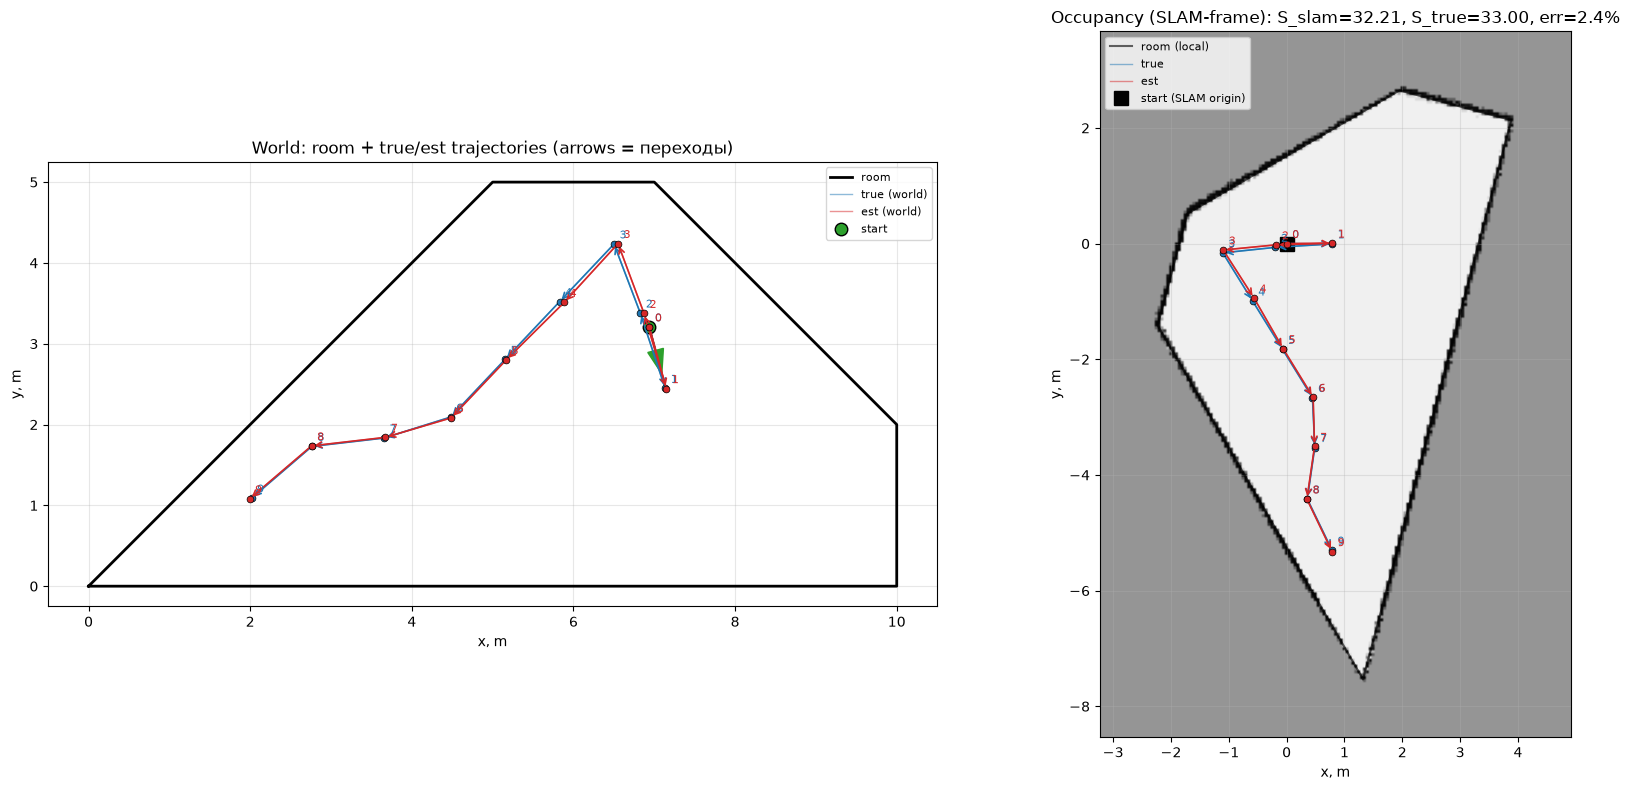

{'S_true': 33.0, 'S_slam': 32.212500000000006, 'err': 0.02386363636363619}


In [770]:
N = 10
ROOM = Room(
    polygon=[
        Point(0.0, 0.0),
        Point(10.0, 0.0),
        Point(10.0, 2.0),
        Point(7.0, 5.0),
        Point(5.0, 5.0),
    ],
)
res = run_single_slam(room=ROOM, seed=23, n_scans=10, n_waypoints=5, greedy_order=True)
print(res)

vis = ScanVisualizer(ROOM)
fig, axes, metrics = vis.plot_slam_result(res['slam'], res['true_poses'])
print(metrics)

### Тестирование на бенчмарке

In [771]:
def benchmark_slam(room, n_runs=20, seed0=0, verbose=True, **kwargs):
    results = []
    for i in range(n_runs):
        r = run_single_slam(room, seed=seed0 + i, **kwargs)
        results.append(r)
        if verbose:
            print(f"[{i+1:3d}/{n_runs}] seed={r['seed']:4d}, ATE_rmse={r['ate_rmse']:.3f} m, "
                  f"ATE_final={r['ate_final']:.3f} m, ang={r['ang_rmse_deg']:5.2f} grad, "
                  f"area_err={100*r['area_err']:5.1f}%")
    return results

In [772]:
def summarize_slam(results):
    fields = [
        ("ATE RMSE, m", "ate_rmse", 1.0),
        ("ATE max, m", "ate_max", 1.0),
        ("ATE final, m", "ate_final", 1.0),
        ("Ang RMSE, deg", "ang_rmse_deg", 1.0),
        ("Area err, %", "area_err", 100.0),
        ("Time, s", "total_time", 1.0),
    ]
    print(f"\n{'metric':18}{'mean':>10}{'median':>10}{'max':>10}{'min':>10}")
    for label, key, scale in fields:
        arr = np.array([r[key] for r in results]) * scale
        print(f"{label:18}{arr.mean():10.3f}{np.median(arr):10.3f}{arr.max():10.3f}{arr.min():10.3f}")

    print("\npass rate:")
    area_err = np.array([r["area_err"] for r in results]) * 100.0
    for thr in [10, 5, 2.5, 2.0]:
        n_ok = int(np.sum(area_err <= thr))
        print(f"Area err <= {thr:.2f} % : {n_ok:3d}/{len(results)} ({100 * n_ok / len(results):.0f}%)")

In [773]:
def replay_worst(results, room, n_show=3, metric="ate_rmse"):
    worst = sorted(results, key=lambda r: -r[metric])[:n_show]
    vis = ScanVisualizer(room)
    for rank, r in enumerate(worst, 1):
        print(f"Worst #{rank}: seed={r['seed']}, ATE_RMSE={r['ate_rmse']:.3f}m, "
              f"ATE_final={r['ate_final']:.3f}m, ang={r['ang_rmse_deg']:.2f} deg "
              f"area_err={100*r['area_err']:.1f}%")
        fig, _, _ = vis.plot_slam_result(r["slam"], r["true_poses"], show=False)
        fig.suptitle(
            f"Worst #{rank}: seed={r['seed']}, ATE_RMSE={r['ate_rmse']:.2f}m, "
            f"ATE_final={r['ate_final']:.3f}m, ang={r['ang_rmse_deg']:.2f} deg "
            f"area_err={100*r['area_err']:.1f}%",
            fontsize=13,
        )
        plt.tight_layout()
        plt.show()

[  1/100] seed=   0, ATE_rmse=0.036 m, ATE_final=0.022 m, ang= 0.28 grad, area_err=  2.4%
[  2/100] seed=   1, ATE_rmse=0.034 m, ATE_final=0.014 m, ang= 0.14 grad, area_err=  2.5%
[  3/100] seed=   2, ATE_rmse=0.028 m, ATE_final=0.034 m, ang= 0.18 grad, area_err=  2.4%
[  4/100] seed=   3, ATE_rmse=0.024 m, ATE_final=0.010 m, ang= 0.12 grad, area_err=  2.5%
[  5/100] seed=   4, ATE_rmse=0.025 m, ATE_final=0.030 m, ang= 0.28 grad, area_err=  2.3%
[  6/100] seed=   5, ATE_rmse=0.028 m, ATE_final=0.010 m, ang= 0.11 grad, area_err=  2.4%
[  7/100] seed=   6, ATE_rmse=0.025 m, ATE_final=0.044 m, ang= 0.28 grad, area_err=  2.5%
[  8/100] seed=   7, ATE_rmse=0.026 m, ATE_final=0.011 m, ang= 0.29 grad, area_err=  2.5%
[  9/100] seed=   8, ATE_rmse=0.025 m, ATE_final=0.013 m, ang= 0.48 grad, area_err=  2.6%
[ 10/100] seed=   9, ATE_rmse=0.023 m, ATE_final=0.028 m, ang= 0.30 grad, area_err=  2.4%
[ 11/100] seed=  10, ATE_rmse=0.030 m, ATE_final=0.028 m, ang= 0.27 grad, area_err=  2.5%
[ 12/100] 

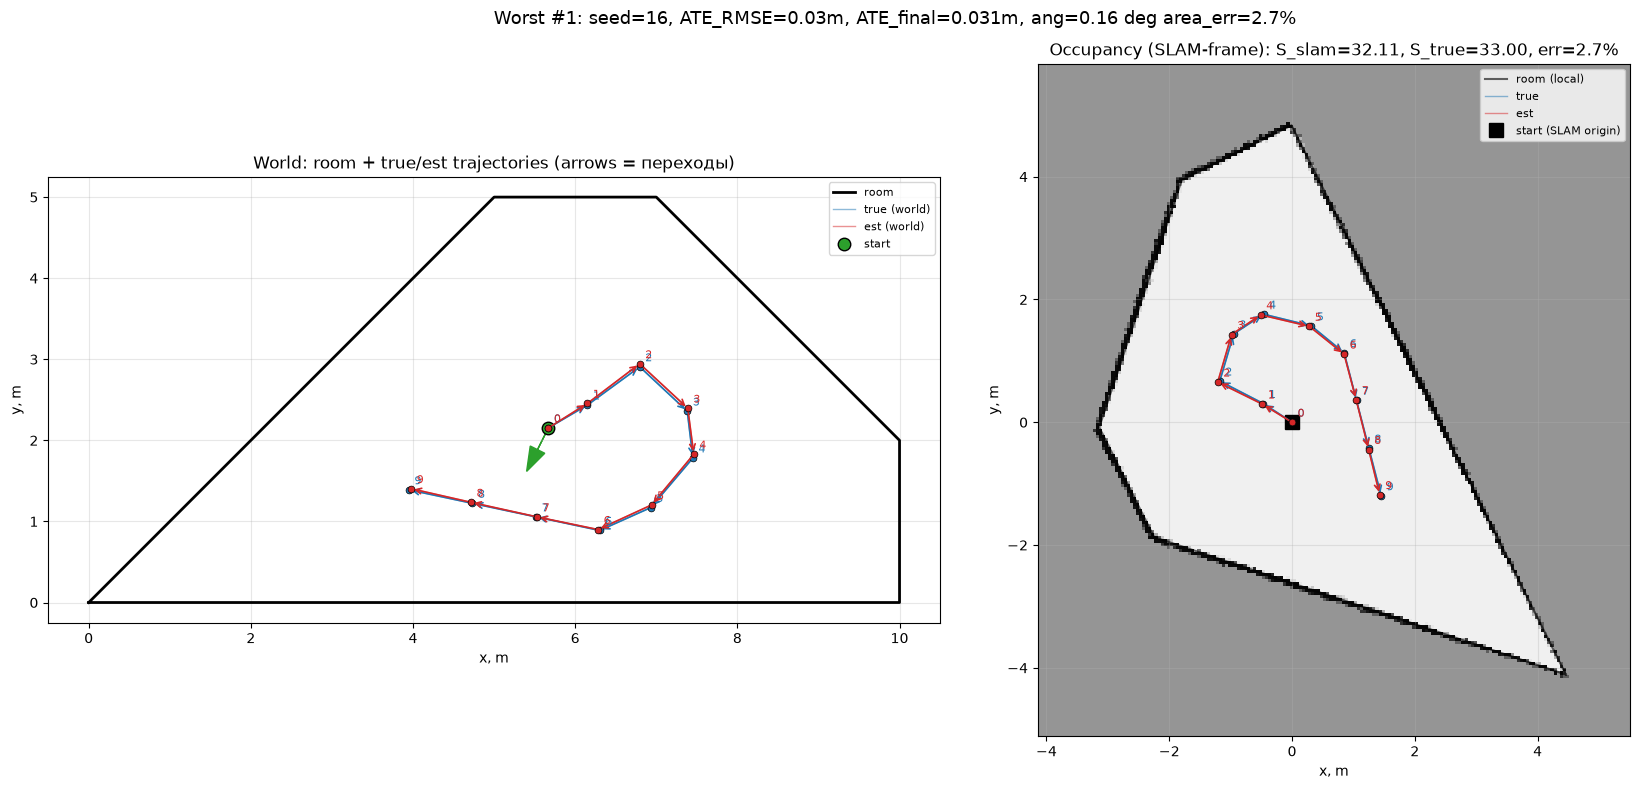

Worst #2: seed=19, ATE_RMSE=0.045m, ATE_final=0.064m, ang=0.20 deg area_err=2.7%


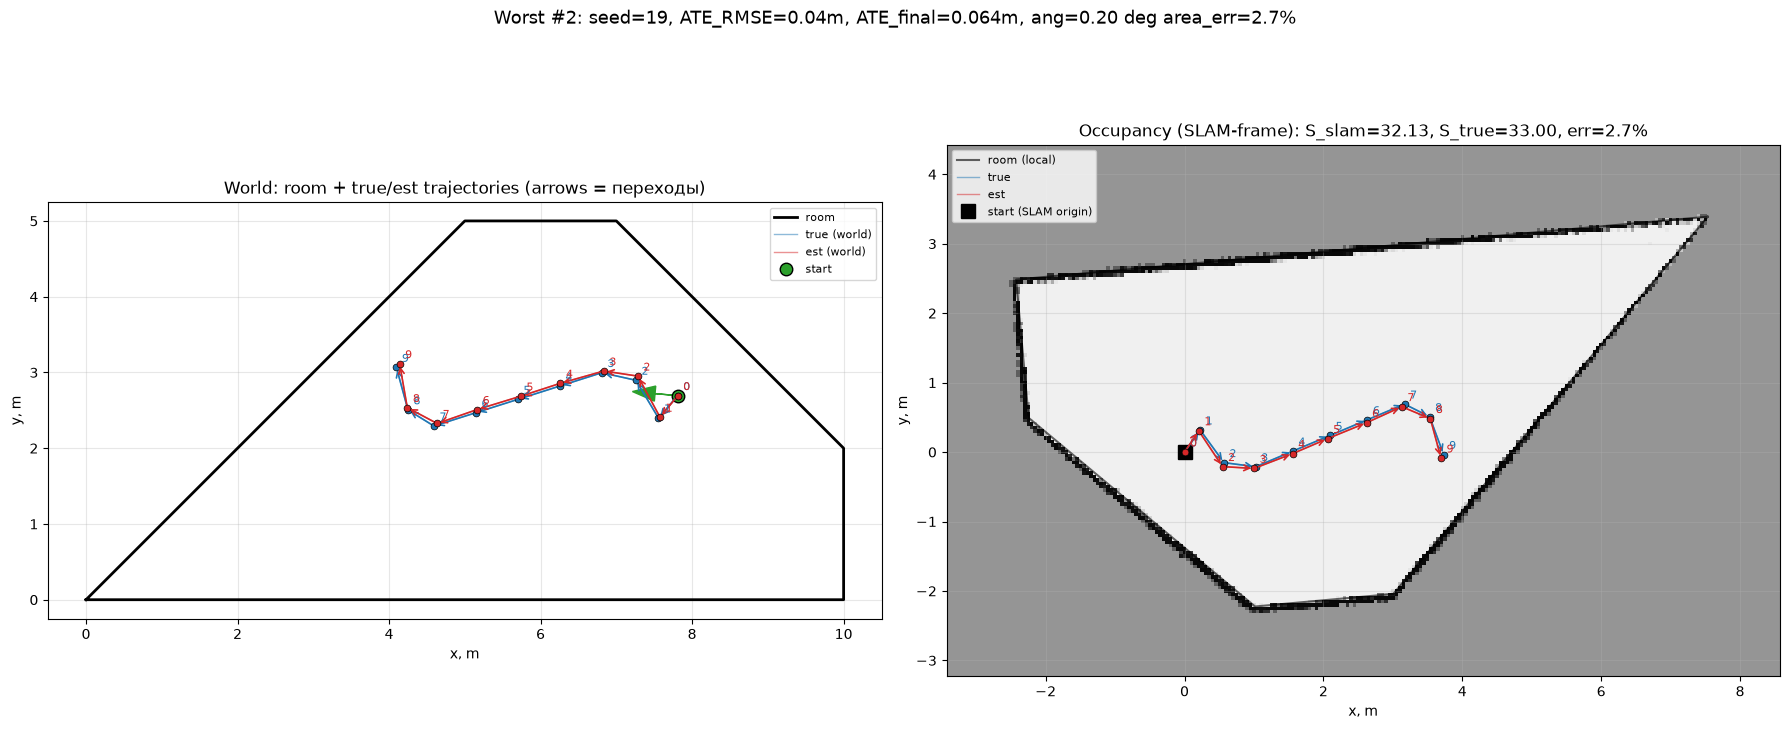

Worst #3: seed=63, ATE_RMSE=0.059m, ATE_final=0.051m, ang=0.26 deg area_err=2.6%


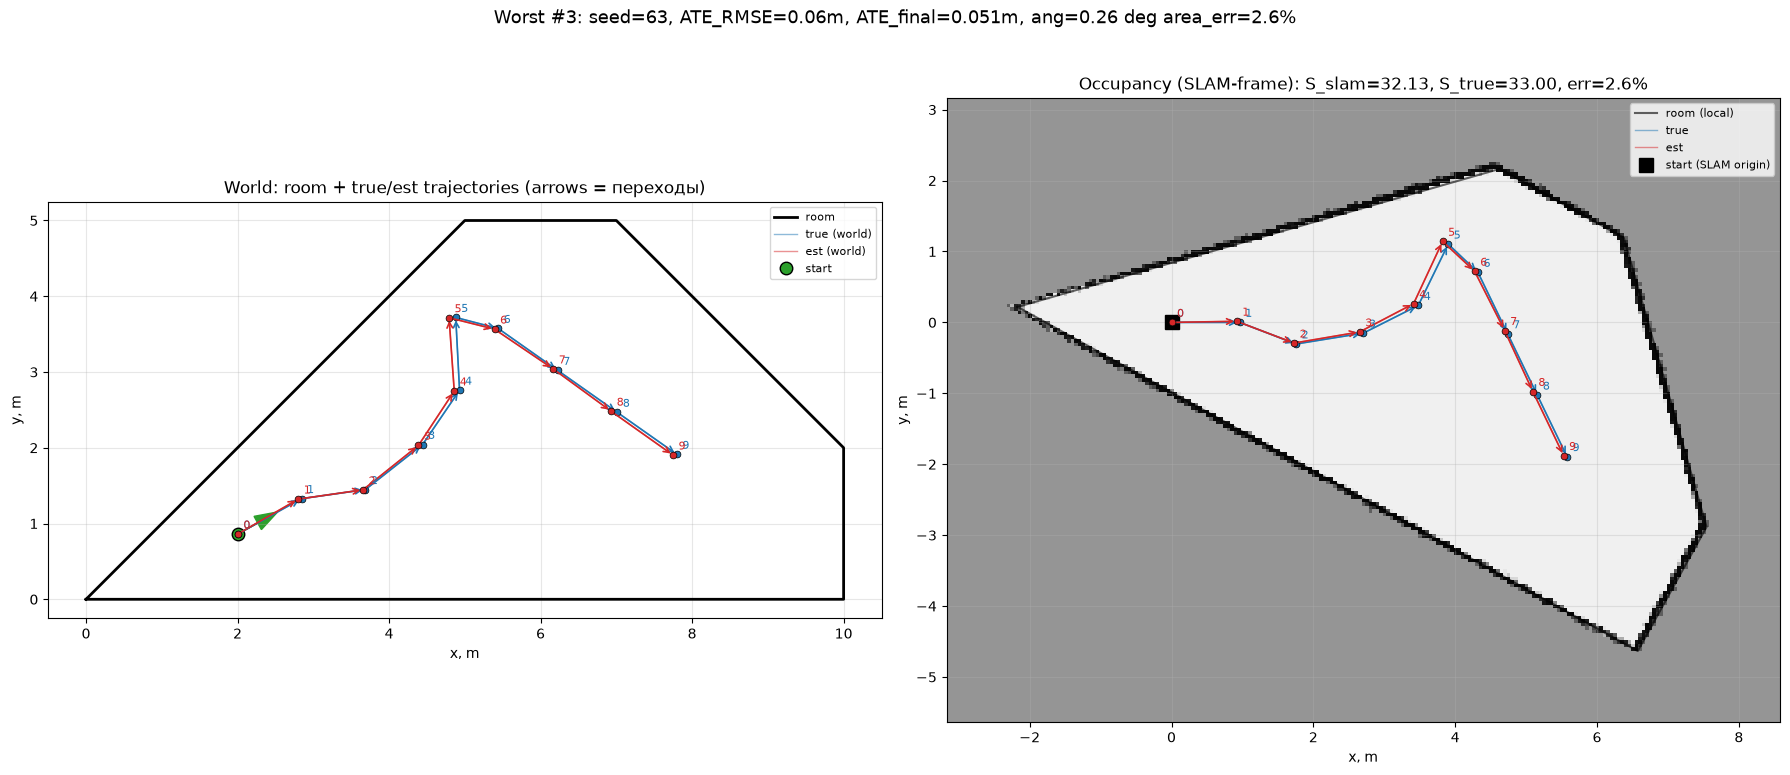

In [774]:
results = benchmark_slam(
    ROOM, n_runs=100, n_scans=10, n_waypoints=5, greedy_order=True,
)
summarize_slam(results)
replay_worst(results, ROOM, n_show=3, metric="area_err")

[  1/100] seed=   0, ATE_rmse=0.019 m, ATE_final=0.023 m, ang= 0.26 grad, area_err=  2.5%
[  2/100] seed=   1, ATE_rmse=0.028 m, ATE_final=0.021 m, ang= 0.35 grad, area_err=  2.6%
[  3/100] seed=   2, ATE_rmse=0.020 m, ATE_final=0.012 m, ang= 0.21 grad, area_err=  2.4%
[  4/100] seed=   3, ATE_rmse=0.025 m, ATE_final=0.033 m, ang= 0.21 grad, area_err=  2.3%
[  5/100] seed=   4, ATE_rmse=0.027 m, ATE_final=0.022 m, ang= 0.32 grad, area_err=  2.4%
[  6/100] seed=   5, ATE_rmse=0.025 m, ATE_final=0.038 m, ang= 0.22 grad, area_err=  2.5%
[  7/100] seed=   6, ATE_rmse=0.041 m, ATE_final=0.045 m, ang= 0.27 grad, area_err=  2.6%
[  8/100] seed=   7, ATE_rmse=0.030 m, ATE_final=0.002 m, ang= 0.35 grad, area_err=  2.5%
[  9/100] seed=   8, ATE_rmse=0.028 m, ATE_final=0.035 m, ang= 0.21 grad, area_err=  2.5%
[ 10/100] seed=   9, ATE_rmse=0.021 m, ATE_final=0.010 m, ang= 0.30 grad, area_err=  2.6%
[ 11/100] seed=  10, ATE_rmse=0.031 m, ATE_final=0.015 m, ang= 0.18 grad, area_err=  2.5%
[ 12/100] 

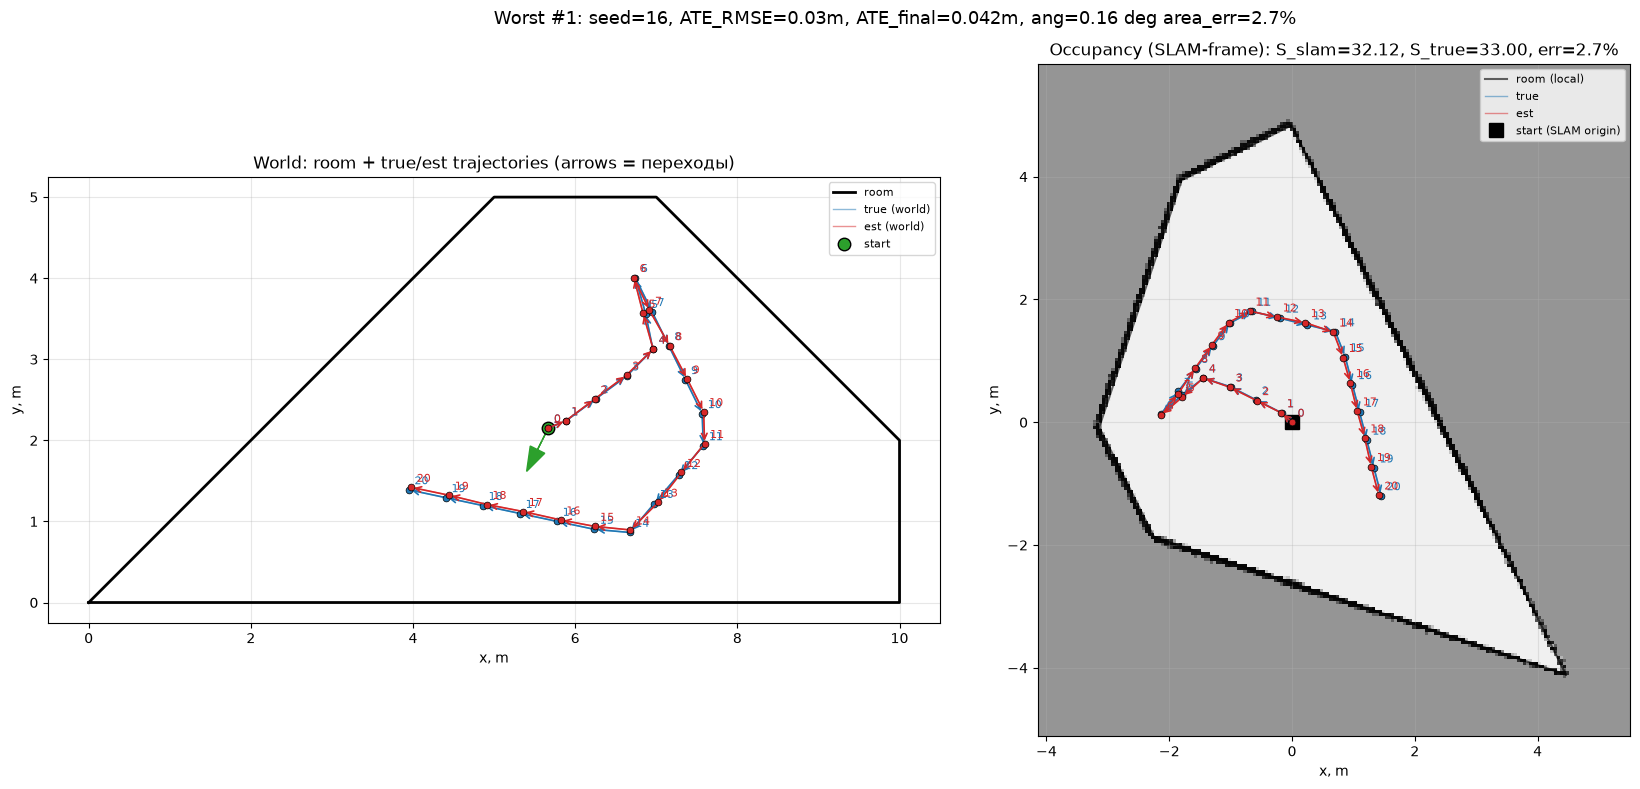

Worst #2: seed=13, ATE_RMSE=0.024m, ATE_final=0.040m, ang=0.21 deg area_err=2.6%


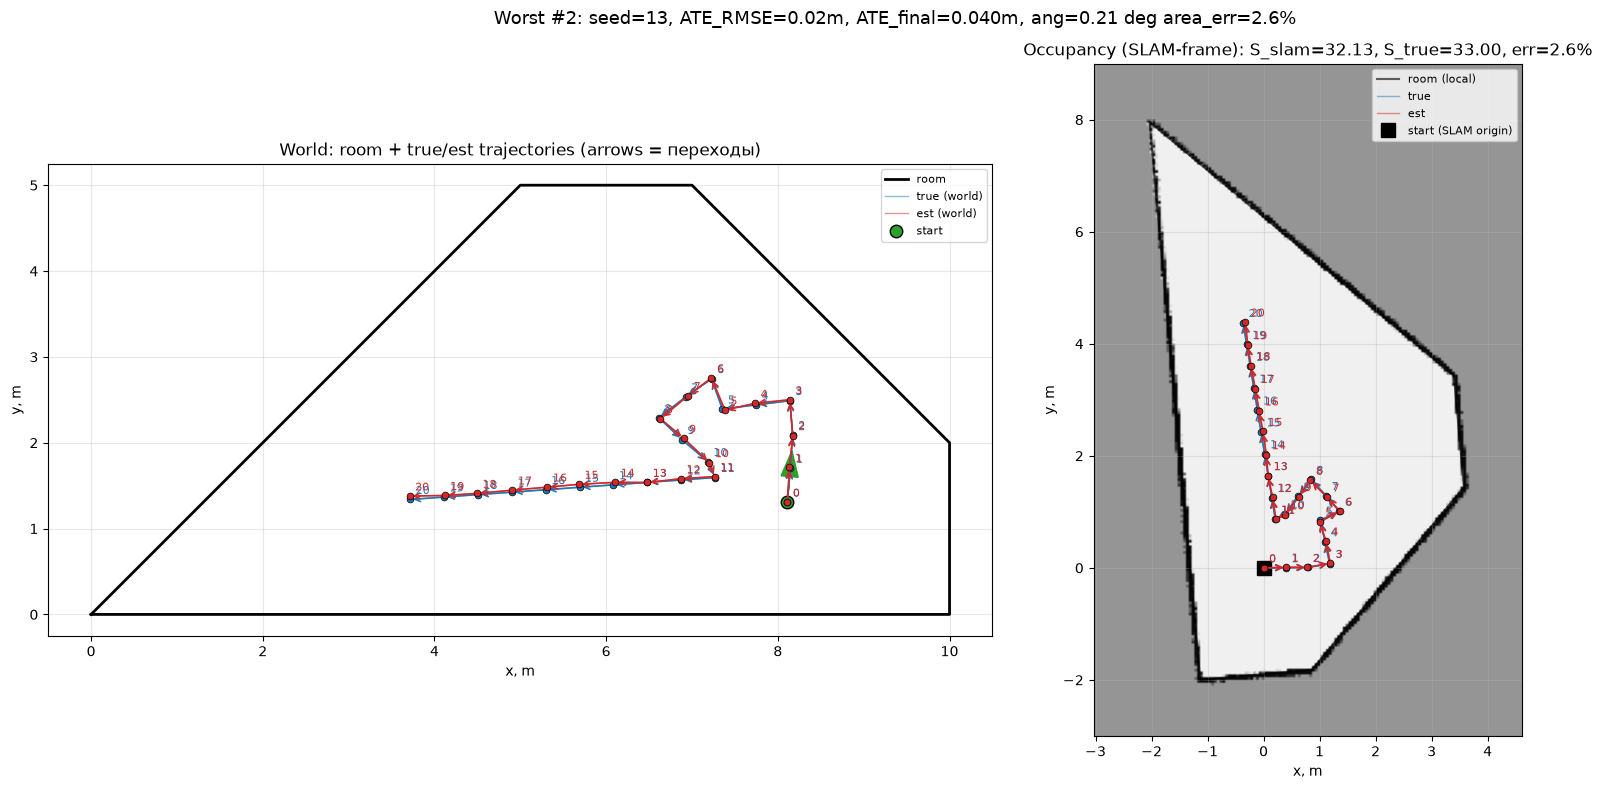

Worst #3: seed=1, ATE_RMSE=0.028m, ATE_final=0.021m, ang=0.35 deg area_err=2.6%


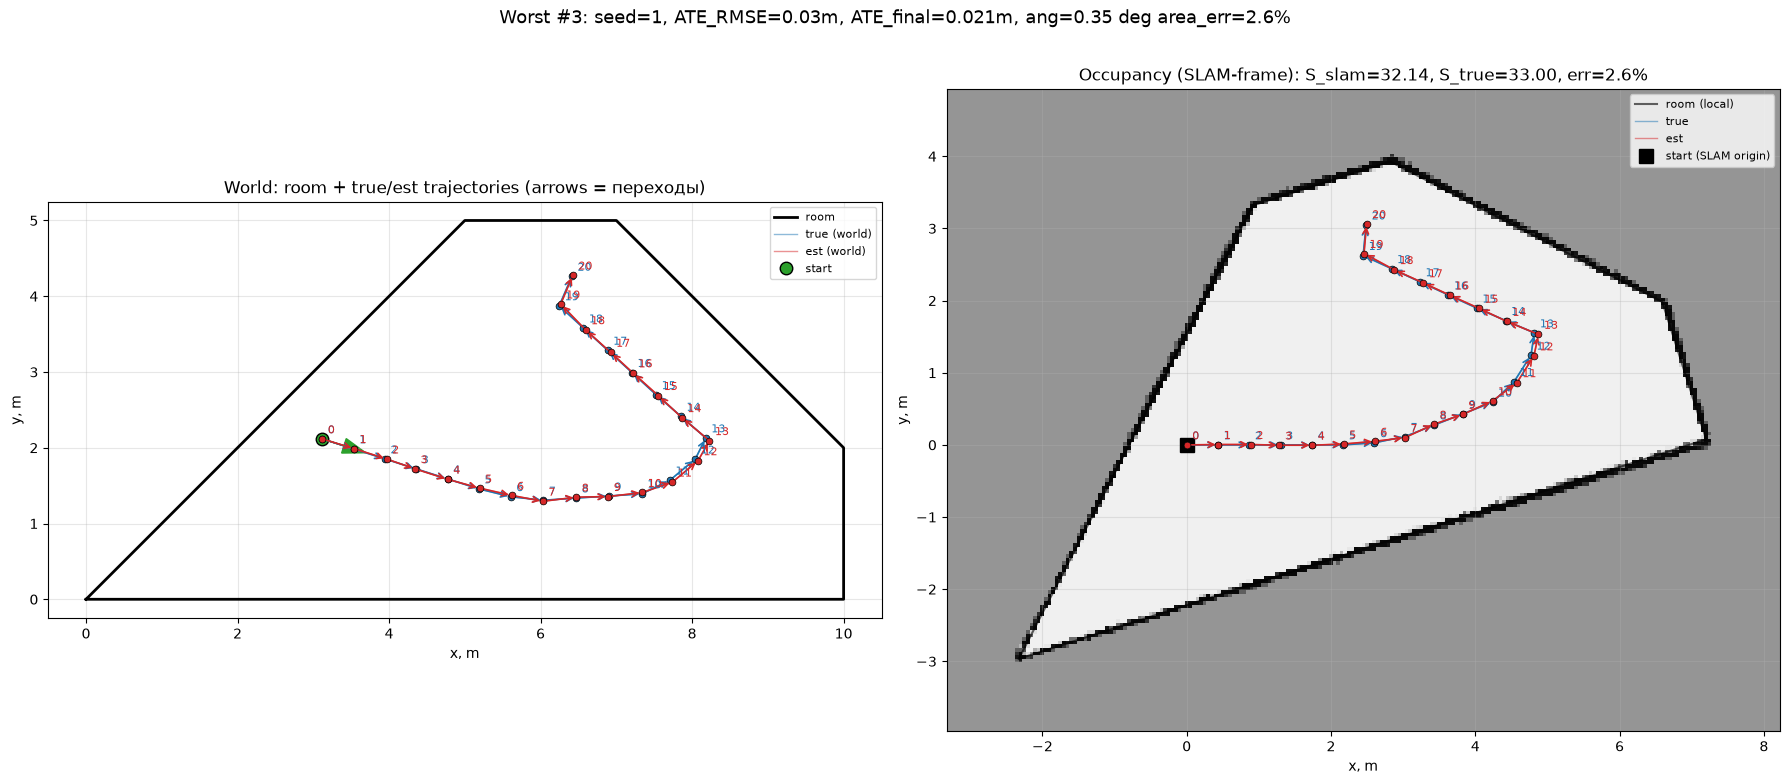

In [775]:
results = benchmark_slam(
    ROOM, n_runs=100, n_scans=21, n_waypoints=7, greedy_order=True,
)
summarize_slam(results)
replay_worst(results, ROOM, n_show=3, metric="area_err")

[  1/100] seed=   0, ATE_rmse=0.033 m, ATE_final=0.021 m, ang= 0.39 grad, area_err=  2.4%
[  2/100] seed=   1, ATE_rmse=0.025 m, ATE_final=0.013 m, ang= 0.31 grad, area_err=  2.5%
[  3/100] seed=   2, ATE_rmse=0.056 m, ATE_final=0.069 m, ang= 0.30 grad, area_err=  2.5%
[  4/100] seed=   3, ATE_rmse=0.027 m, ATE_final=0.033 m, ang= 0.29 grad, area_err=  2.3%
[  5/100] seed=   4, ATE_rmse=0.036 m, ATE_final=0.043 m, ang= 0.28 grad, area_err=  2.3%
[  6/100] seed=   5, ATE_rmse=0.029 m, ATE_final=0.009 m, ang= 0.16 grad, area_err=  2.4%
[  7/100] seed=   6, ATE_rmse=0.024 m, ATE_final=0.026 m, ang= 0.25 grad, area_err=  2.5%
[  8/100] seed=   7, ATE_rmse=0.037 m, ATE_final=0.028 m, ang= 0.25 grad, area_err=  2.4%
[  9/100] seed=   8, ATE_rmse=0.029 m, ATE_final=0.020 m, ang= 0.28 grad, area_err=  2.4%
[ 10/100] seed=   9, ATE_rmse=0.028 m, ATE_final=0.012 m, ang= 0.25 grad, area_err=  2.4%
[ 11/100] seed=  10, ATE_rmse=0.046 m, ATE_final=0.020 m, ang= 0.36 grad, area_err=  2.6%
[ 12/100] 

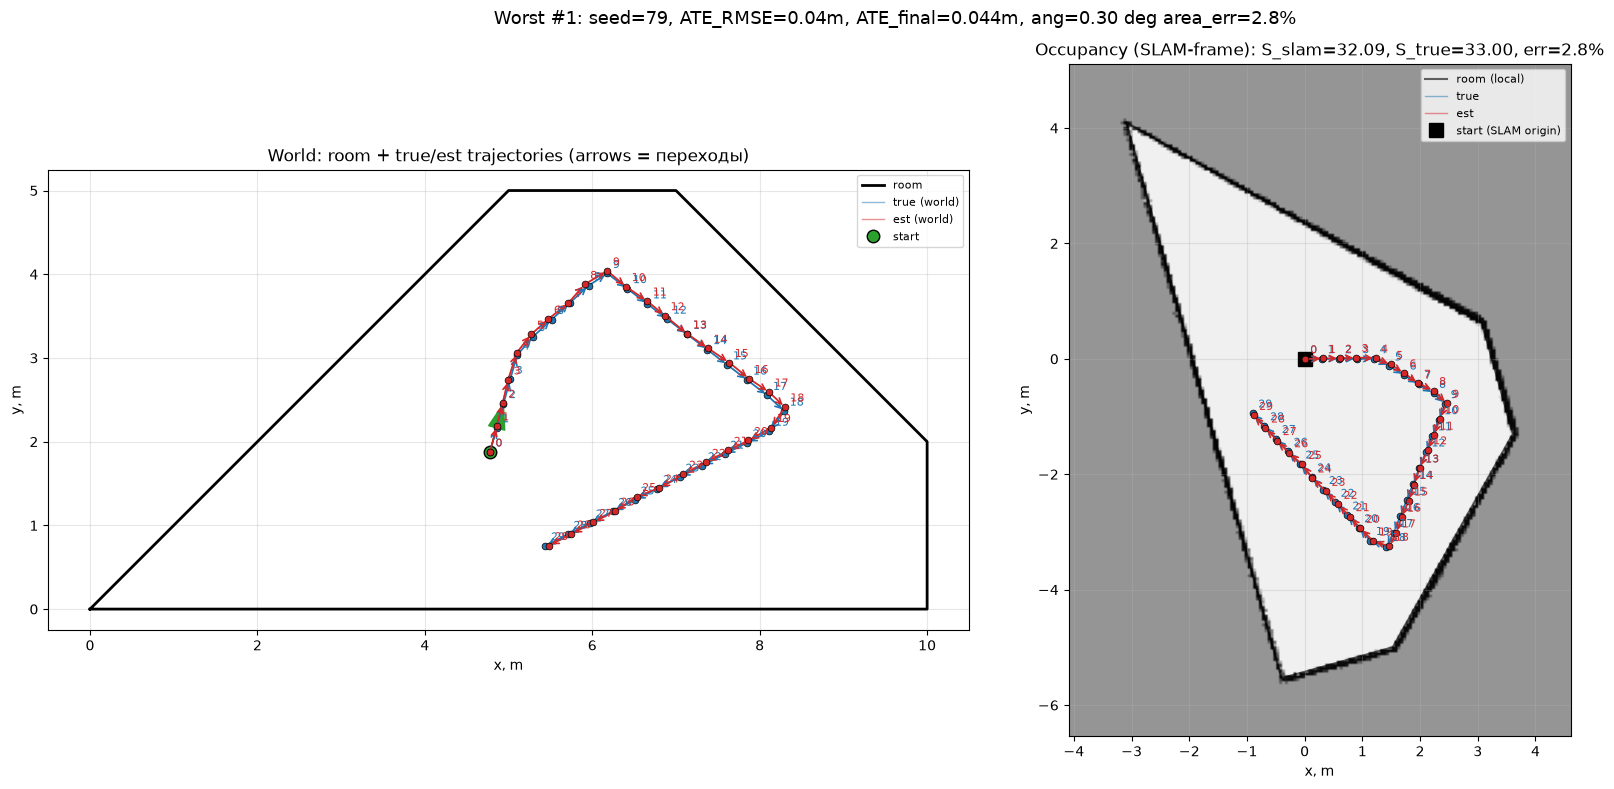

Worst #2: seed=70, ATE_RMSE=0.030m, ATE_final=0.009m, ang=0.26 deg area_err=2.7%


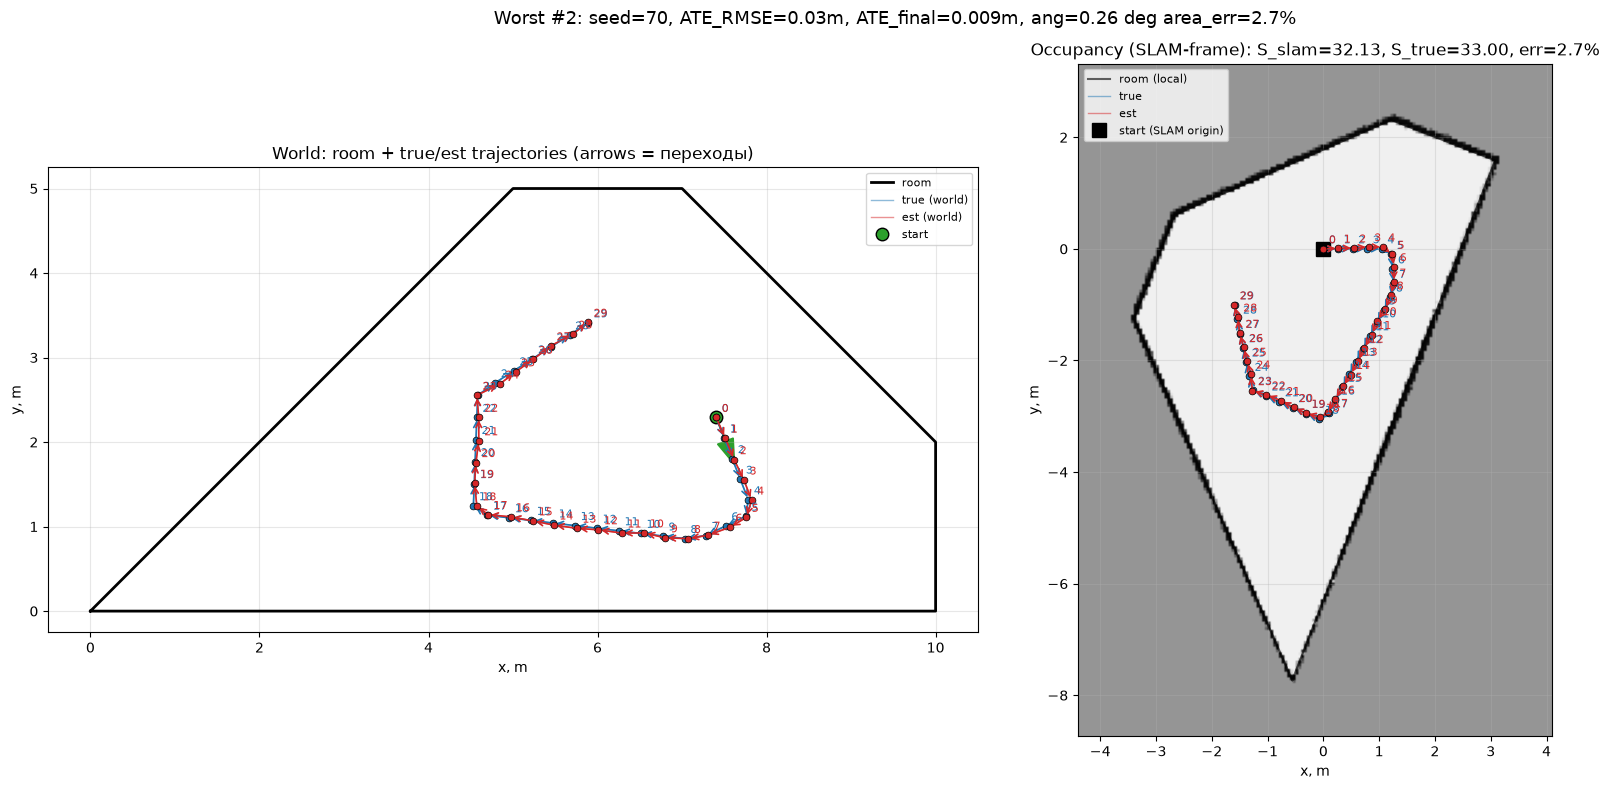

Worst #3: seed=56, ATE_RMSE=0.024m, ATE_final=0.019m, ang=0.27 deg area_err=2.6%


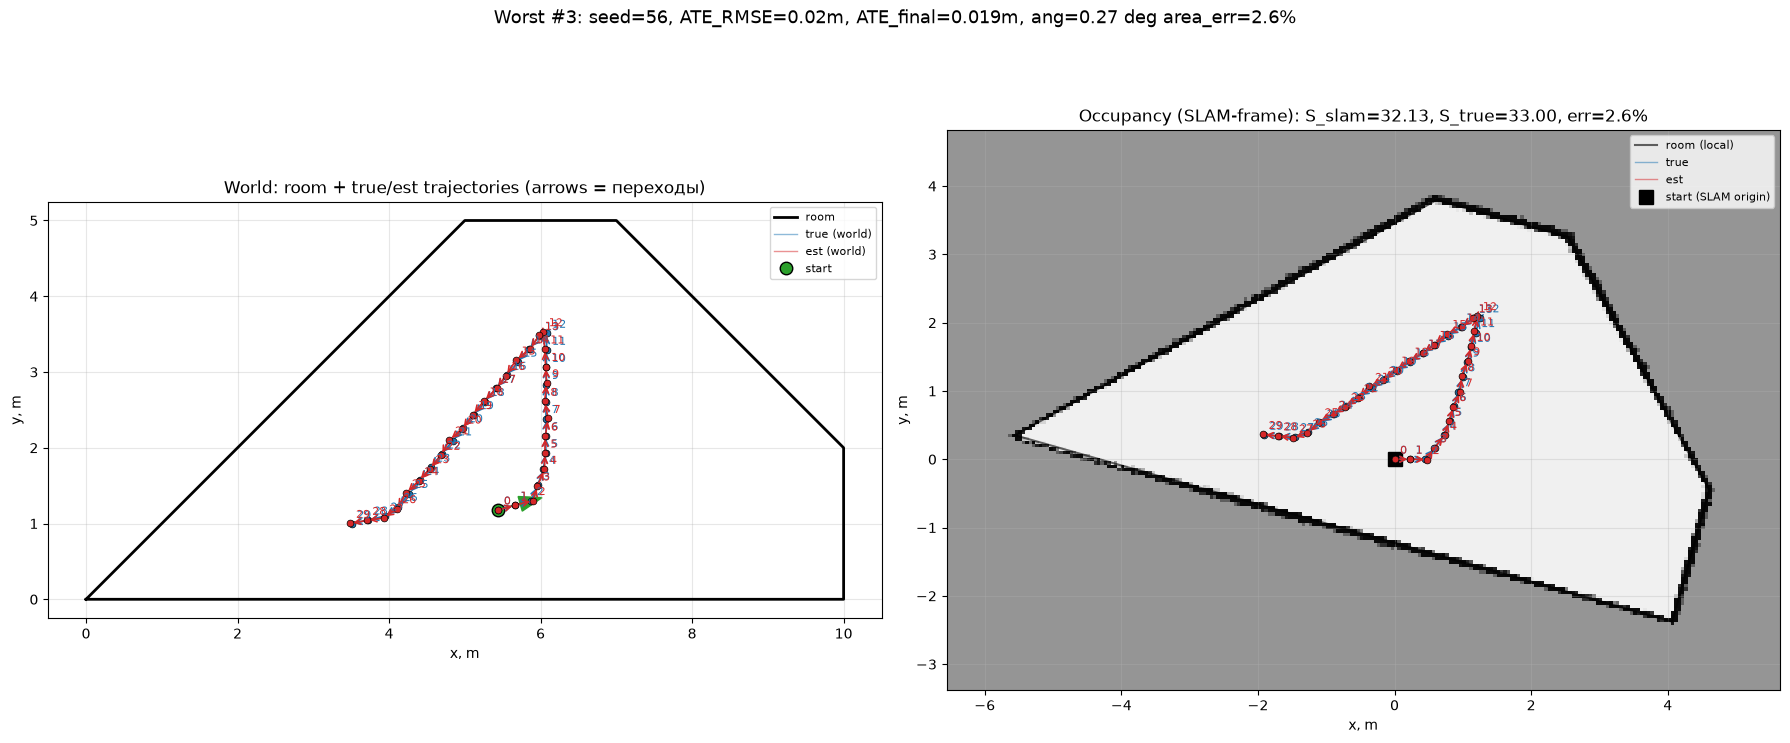

In [776]:
results = benchmark_slam(
    ROOM, n_runs=100, n_scans=30, n_waypoints=5, greedy_order=True,
)
summarize_slam(results)
replay_worst(results, ROOM, n_show=3, metric="area_err")